In [1]:
import numpy as np
import xarray as xr
import tensorflow as tf
import joblib
import sys
import os
sys.path.append(os.path.abspath(".."))
from src.config import load_paths
from model.model import read_scale_data
from evaluation.flux_energy import parsavel_avarge_cofficents
from evaluation.flux_energy import zonally_avarge
import matplotlib.pyplot as plt

I0000 00:00:1789557339.842564 2957666 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1789557339.884923 2957666 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1789557342.664165 2957666 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


In [2]:
Y_scaled = np.zeros((20480, 144))
Y_predicted = np.zeros((20480, 144))
omega_hat = np.zeros((20480, 1, 6, 6, 4))
cgz = np.zeros((20480, 1, 6, 6, 4))
ntri_dict = {}
for tag in  ["land", "ocean"]:
				name_model = f"cnn_coarsed_{tag}.keras"
				paths = load_paths()
				ml_model_dir = paths["ml_model_dir"]
				fname_model = f"cnn_coarsed_{tag}.keras"
				model = tf.keras.models.load_model(
												ml_model_dir + fname_model,
												custom_objects=False, compile=False)
				season_tag = "Nov"
				data_base_dir = paths[f"data_base_dir_{season_tag}"]
				ds_name = f"corsed_action_{tag}.pkl"
				scaler = joblib.load(paths["save_dir"] + "/scaler/" + f"scaler_X_{tag}.pkl")
				ds = joblib.load(data_base_dir + ds_name)
				X_scaler = scaler.transform(ds["X"][:, 0, :])
				Y_s = np.log(ds["Y"][:, 0, :] + 1).reshape(-1, 144)
				cgz[ds["ntri"], ...] = ds["cgz"]
				omega_hat[ds["ntri"], ...] = ds["omega_hat"]
				ntri_dict[f"ntri_{tag}"] = ds["ntri"]
				Y_scaled[ds["ntri"], ...] = np.nan_to_num(Y_s, 0.0)
				Y_predicted[ds["ntri"]] = model.predict(X_scaler)

E0000 00:00:1789557353.014778 2957666 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


270/270 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
371/371 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


In [3]:
for tri_tag in ["land", "ocean"]:
    MSE = np.mean((Y_scaled[ntri_dict[f"ntri_{tri_tag}"]]
                    - Y_predicted[ntri_dict[f"ntri_{tri_tag}"]])**2, axis=0)
    var = np.var(Y_scaled[ntri_dict[f"ntri_{tri_tag}"]], axis=0)
    R2 = 1 - MSE/var
    print(f"MSE {tri_tag} : {MSE.mean()}")
    print(f"R2 {tri_tag} : {R2.mean()}")

MSE land : 1.888665781993077
R2 land : 0.6434474430455683
MSE ocean : 1.861890109905526
R2 ocean : 0.5739181558607387


In [4]:
N_test = np.expm1(Y_scaled)
N_pred = np.expm1(Y_predicted)
for tag_land_ocean in ["land", "ocean"]:
				MAE    = np.mean(np.abs(N_test[ntri_dict[f"ntri_{tag_land_ocean}"]]
							 - N_pred[ntri_dict[f"ntri_{tag_land_ocean}"]]), axis=0)

				save_dir = paths["save_dir"]

				(_, _, y_train, _, _, _, _, _, _, _, _, 
									_, _, _, _, _, _) = read_scale_data(save_dir, land_ocean_tag=tag_land_ocean, coarse_action_dir_jan=paths["coarse_action_dir_jan"],
                                                                        physics=False)
				N_train = np.expm1(y_train)
				std    = np.std(N_train, axis=0)
				NMAE   = MAE/std
				del y_train
				N_base_line = np.mean(N_train, axis=0)
				mae_base_line = np.mean(np.abs(N_test[ntri_dict[f"ntri_{tag_land_ocean}"]]
								    - N_base_line), axis=0)
				score = 1 - MAE/mae_base_line
				del N_train
				print(f"MAE {tag_land_ocean} : {MAE.mean()}")
				print(f"NMAE {tag_land_ocean} : {NMAE.mean()}")
				print(f"score {tag_land_ocean} : {score.mean()}")

Loading databases...
Combined shapes → X_train: (8622, 217, 111), y_train: (8622, 217, 6, 6, 4)
Combined shapes → X_test:  (8622, 44, 111), y_test:  (8622, 44, 6, 6, 4)
Combined shapes → X_val:   (8622, 30, 111), y_val:   (8622, 30, 6, 6, 4)
MAE land : 13418.869615352467
NMAE land : 0.16055020042924392
score land : 0.48110398738851146
Loading databases...
Combined shapes → X_train: (11858, 217, 102), y_train: (11858, 217, 6, 6, 4)
Combined shapes → X_test:  (11858, 44, 102), y_test:  (11858, 44, 6, 6, 4)
Combined shapes → X_val:   (11858, 30, 102), y_val:   (11858, 30, 6, 6, 4)
MAE ocean : 8296.085852038026
NMAE ocean : 0.23881167720062896
score ocean : 0.45962262426991035


In [5]:
tag_season = "Nov"
coarse_action_dir      = paths[f"coarse_action_dir_{tag_season}"]
with xr.open_dataset(coarse_action_dir + "coarse_gw_spectrum_group_1_fileslide_0.nc") as ds1:
        k_lunch = ds1.k.data
        l_lunch = ds1.l.data
        m_lunch = ds1.m.data

In [6]:
omega_hat = omega_hat.reshape(-1, 144)
N_test = np.expm1(Y_scaled)
N_pred = np.expm1(Y_predicted)
E_pred = np.sum(N_pred*omega_hat, axis=1)
E_test = np.sum(N_test*omega_hat, axis=1)
bias      = (np.mean(E_pred) - np.mean(E_test))/np.mean(E_test)
r         = np.corrcoef(E_test, E_pred)[0, 1]

In [7]:
print(f"bias of energy : {bias}")
print(f"corrolation {r}")

bias of energy : -0.4099083262876082
corrolation 0.5218992520475274


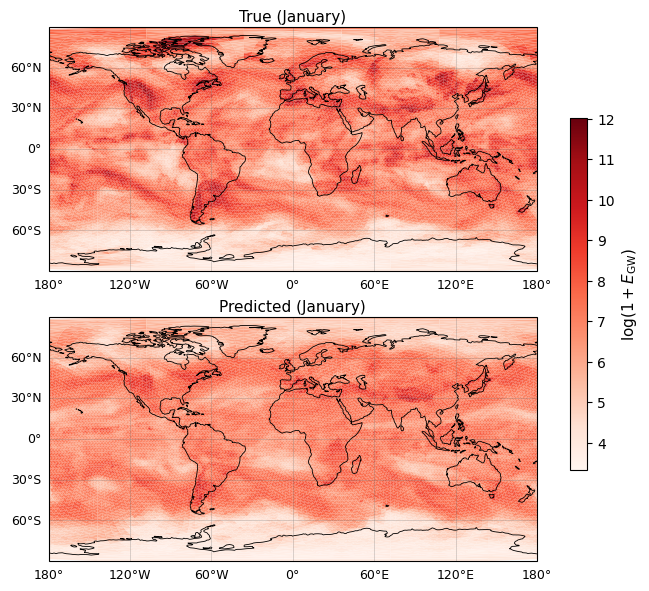

--> saved to /work/bb1097/b383521/plots/paper_plots/E_test_vs_model_jan.png and /work/bb1097/b383521/plots/paper_plots/E_test_vs_model_jan.pdf


In [8]:
import os
import cartopy.crs as ccrs
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr
from matplotlib.collections import PolyCollection


def plot_global_map_pair(
    var_top,
    var_bottom,
    save_dir,
    filename="global_flux_map_pair",
    title_top="True",
    title_bottom="Predicted",
    cbar_label=r"$\log(1+E_{GW})$",
    cmap="Reds",
    vmin=None,
    vmax=None,
    fontsize=11,  # Standard publication size
):
    gridfil = xr.open_dataset(
        "/work/bb1097/b381585/data/icon_grid_0012_R02B04_G.nc"
    )

    clon_vertices = np.rad2deg(gridfil.clon_vertices.values)
    clat_vertices = np.rad2deg(gridfil.clat_vertices.values)

    clon_vertices = np.where(
        clon_vertices < -180.0, clon_vertices + 360.0, clon_vertices
    )
    clon_vertices = np.where(
        clon_vertices > 180.0, clon_vertices - 360.0, clon_vertices
    )
    triangles = np.stack([clon_vertices, clat_vertices], axis=-1)

    if vmin is None:
        vmin = min(np.nanmin(var_top), np.nanmin(var_bottom))
    if vmax is None:
        vmax = max(np.nanmax(var_top), np.nanmax(var_bottom))

    norm = plt.Normalize(vmin=vmin, vmax=vmax)
    cmap_obj = plt.get_cmap(cmap)

    # 2 rows, 1 column for vertical layout (Standard paper width 7.0 in)
    fig, axes = plt.subplots(
        2,
        1,
        figsize=(7.0, 5.8),
        subplot_kw=dict(projection=ccrs.PlateCarree()),
        constrained_layout=True,
    )

    datasets = [
        (var_top, title_top, axes[0]),
        (var_bottom, title_bottom, axes[1]),
    ]

    for var, subtitle, ax in datasets:
        colors = cmap_obj(norm(var))

        ax.set_global()
        ax.coastlines(linewidth=0.6, zorder=2)

        gl = ax.gridlines(
            draw_labels=True,
            linewidth=0.4,
            color="dimgray",
            alpha=0.45,
            zorder=2,
        )
        gl.top_labels = False
        gl.right_labels = False
        gl.xlabel_style = {"size": fontsize - 2}
        gl.ylabel_style = {"size": fontsize - 2}

        coll = PolyCollection(
            triangles,
            array=None,
            fc=colors,
            edgecolors="none",
            linewidth=0.05,
            transform=ccrs.Geodetic(),
            zorder=0,
        )
        ax.add_collection(coll)

        # Unbolded subpanel title
        ax.set_title(subtitle, fontsize=fontsize, pad=4)

    # ScalarMappable for colorbar
    sm = plt.cm.ScalarMappable(cmap=cmap_obj, norm=norm)
    sm.set_array([])

    # Vertical colorbar on the right with compact width and padding
    cbar = fig.colorbar(
        sm,
        ax=axes,
        orientation="vertical",
        fraction=0.03,
        pad=0.03,
        shrink=0.85,
    )
    cbar.set_label(cbar_label, fontsize=fontsize, fontweight="normal")
    cbar.ax.tick_params(labelsize=fontsize - 1)

    os.makedirs(save_dir, exist_ok=True)
    outpath_png = os.path.join(save_dir, f"{filename}.png")
    outpath_pdf = os.path.join(save_dir, f"{filename}.pdf")

    plt.savefig(outpath_png, dpi=400, bbox_inches="tight")
    plt.savefig(outpath_pdf, dpi=400, bbox_inches="tight")
    plt.show()
    print(f"--> saved to {outpath_png} and {outpath_pdf}")



vmin_jan = min(np.min(np.log1p(E_test)), np.min(np.log1p(E_pred)))
vmax_jan = max(np.max(np.log1p(E_test)), np.max(np.log1p(E_pred)))

plot_global_map_pair(
    np.log1p(E_test),
    np.log1p(E_pred),
    save_dir="/work/bb1097/b383521/plots/paper_plots/",
    filename="E_test_vs_model_jan",
    title_top="True (January)",
    title_bottom="Predicted (January)",
    cbar_label=r"$\log(1+E_{\mathrm{GW}})$",
    cmap="Reds",
    vmin=vmin_jan,
    vmax=vmax_jan,
)

In [9]:
ntri = ds["ntri"]
k = k_lunch[None, None, :, None, None]
l = l_lunch[None, None, None, :, None]
uw_test = np.sum(-N_test.reshape(20480, 1, 6, 6, 4)*cgz*k, axis=(2, 3, 4))
uw_pred = np.sum(-N_pred.reshape(20480, 1, 6, 6, 4)*cgz*k, axis=(2, 3, 4))
vw_test =  np.sum(-N_test.reshape(20480, 1, 6, 6, 4)*cgz*l, axis=(2, 3, 4))
vw_pred =  np.sum(-N_pred.reshape(20480, 1, 6, 6, 4)*cgz*l, axis=(2, 3, 4))

In [10]:
pars_coff = parsavel_avarge_cofficents(decomposed_dir=paths["decomposed_dir"],
                                        tri_list_dir=paths["tri_list_dir"])
ntri = ds["ntri"]
k = k_lunch[None, None, :, None, None]
l = l_lunch[None, None, None, :, None]
uw_test = np.sum(N_test.reshape(20480, 1, 6, 6, 4)*cgz*k, axis=(2, 3, 4))*pars_coff
uw_pred = np.sum(N_pred.reshape(20480, 1, 6, 6, 4)*cgz*k, axis=(2, 3, 4))*pars_coff
vw_test =  np.sum(N_test.reshape(20480, 1, 6, 6, 4)*cgz*l, axis=(2, 3, 4))*pars_coff
vw_pred =  np.sum(N_pred.reshape(20480, 1, 6, 6, 4)*cgz*l, axis=(2, 3, 4))*pars_coff

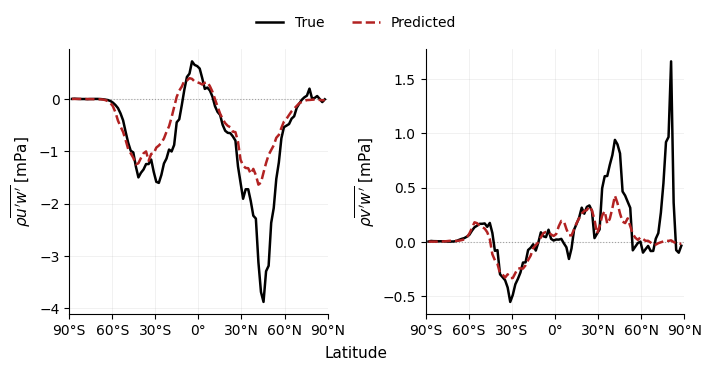

In [11]:
uw_test_avrage, lat_bins = zonally_avarge(var=uw_test*1000, 
                                grid_file=paths["grid_file_low"])
uw_pred_avrage, lat_bins = zonally_avarge(var=uw_pred*1000, 
                                grid_file=paths["grid_file_low"])
vw_pred_avrage, lat_bins = zonally_avarge(var=vw_pred*1000, 
                                grid_file=paths["grid_file_low"])
vw_test_avrage, lat_bins = zonally_avarge(var=vw_test*1000, 
                                grid_file=paths["grid_file_low"])


lat = 0.5 * (lat_bins[:-1] + lat_bins[1:])
def plot_zonal_mean_pair(
    lat,
    uw_test,
    uw_pred,
    vw_test,
    vw_pred,
    savename="zonal_mean_uw_vw",
    fontsize=11,  # Standard paper font size (9–11 pt)
):
    # Standard 2-column paper figure dimensions
    fig, axes = plt.subplots(
        1, 2, figsize=(7.0, 3.2), sharey=False, constrained_layout=True
    )

    datasets = [
        (r"$\rho\overline{u'w'}$ [mPa]", uw_test, uw_pred, axes[0]),
        (r"$\rho\overline{v'w'}$ [mPa]", vw_test, vw_pred, axes[1]),
    ]

    handles = []

    for ylabel, true_vals, pred_vals, ax in datasets:
        ax.axhline(0, color="gray", lw=0.8, ls=":", alpha=0.7)

        (l1,) = ax.plot(lat, true_vals, "-", color="black", lw=1.8, label="True")
        (l2,) = ax.plot(
            lat, pred_vals, "--", color="firebrick", lw=1.8, label="Predicted"
        )

        ax.set_xlim(lat.min(), lat.max())

        # Clean degree-formatted latitude ticks
        xticks = np.arange(-90, 91, 30)
        xticklabels = [
            f"{abs(x)}°S" if x < 0 else (f"{x}°N" if x > 0 else "0°")
            for x in xticks
        ]
        ax.set_xticks(xticks)
        ax.set_xticklabels(xticklabels, fontsize=fontsize - 1)

        ax.tick_params(axis="both", labelsize=fontsize - 1)
        ax.grid(alpha=0.25, lw=0.5)
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

        ax.set_ylabel(ylabel, fontsize=fontsize)

        if ax == axes[0]:
            handles = [l1, l2]

    # Centered figure-level x-axis label
    fig.supxlabel("Latitude", fontsize=fontsize)

    # Clean upper legend
    fig.legend(
        handles=handles,
        labels=["True", "Predicted"],
        loc="lower center",
        ncol=2,
        bbox_to_anchor=(0.5, 1.01),
        fontsize=fontsize - 1,
        frameon=False,
    )

    plt.savefig(
        f"/work/bb1097/b383521/plots/paper_plots/{savename}.png",
        dpi=400,
        bbox_inches="tight",
    )
    plt.savefig(
        f"/work/bb1097/b383521/plots/paper_plots/{savename}.pdf",
        dpi=400,
        bbox_inches="tight",
    )
    plt.show()
plot_zonal_mean_pair(
    lat,
    uw_test_avrage,
    uw_pred_avrage,
    vw_test_avrage,
    vw_pred_avrage,
    savename="zonal_mean_uw_vw",
)

Using shared color range: vmin=-4.9165, vmax=4.9165


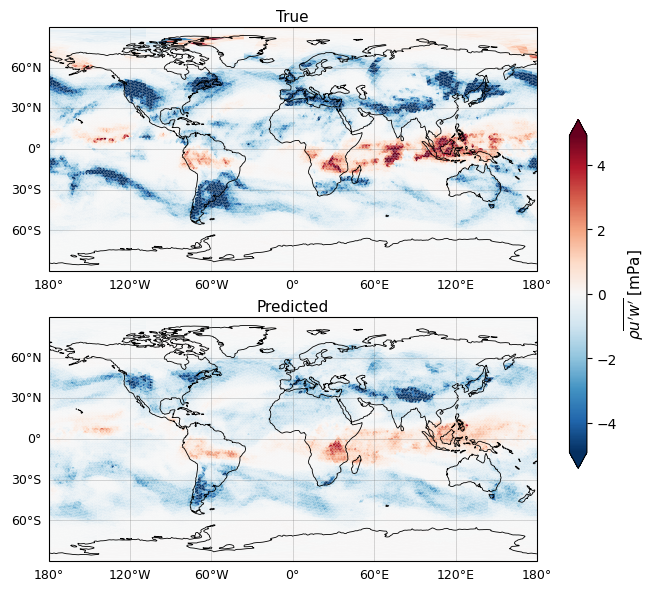

--> saved to /work/bb1097/b383521/plots/paper_plots/uw_momentum_flux_mpa_nov.png and /work/bb1097/b383521/plots/paper_plots/uw_momentum_flux_mpa_nov.pdf
Using shared color range: vmin=-1.7060, vmax=1.7060


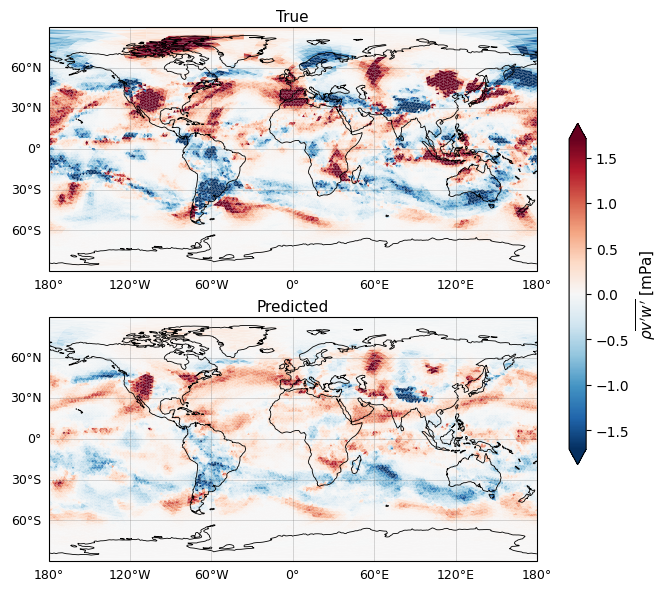

--> saved to /work/bb1097/b383521/plots/paper_plots/vw_momentum_flux_mpa_nov.png and /work/bb1097/b383521/plots/paper_plots/vw_momentum_flux_mpa_nov.pdf


In [12]:
import os
import cartopy.crs as ccrs
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr
from matplotlib.collections import PolyCollection
from matplotlib.colors import TwoSlopeNorm


def plot_global_map_flux_pair(
    var_top,
    var_bottom,
    save_dir,
    filename="global_momentum_flux_map_pair",
    title_top="True",
    title_bottom="Predicted",
    cbar_label=r"$\rho\overline{u'w'}$ [mPa]",
    cmap="RdBu_r",
    vmin=None,
    vmax=None,
    percentile_clip=True,
    p_low=2,
    p_high=98,
    symmetric=True,
    fontsize=11,
):
    var_top = np.asarray(var_top, dtype=float)
    var_bottom = np.asarray(var_bottom, dtype=float)

    gridfil = xr.open_dataset(
        "/work/bb1097/b381585/data/icon_grid_0012_R02B04_G.nc"
    )
    clon_vertices = np.rad2deg(gridfil.clon_vertices.values)
    clat_vertices = np.rad2deg(gridfil.clat_vertices.values)
    gridfil.close()

    clon_vertices = np.where(
        clon_vertices < -180.0, clon_vertices + 360.0, clon_vertices
    )
    clon_vertices = np.where(
        clon_vertices > 180.0, clon_vertices - 360.0, clon_vertices
    )
    triangles = np.stack([clon_vertices, clat_vertices], axis=-1)

    # ---------------------------
    # Shared color range across BOTH panels
    # ---------------------------
    if vmin is None or vmax is None:
        combined = np.concatenate(
            [var_top[np.isfinite(var_top)], var_bottom[np.isfinite(var_bottom)]]
        )
        if percentile_clip:
            p_lo_val, p_hi_val = np.nanpercentile(combined, [p_low, p_high])
            if symmetric:
                vmax_abs = max(abs(p_lo_val), abs(p_hi_val))
                vmin, vmax = -vmax_abs, vmax_abs
            else:
                vmin, vmax = p_lo_val, p_hi_val
        else:
            vmin, vmax = np.nanmin(combined), np.nanmax(combined)

    print(f"Using shared color range: vmin={vmin:.4f}, vmax={vmax:.4f}")

    cmap_obj = plt.get_cmap(cmap)
    norm = TwoSlopeNorm(vmin=vmin, vcenter=0.0, vmax=vmax)

    # 2 rows, 1 column vertical stack layout (Standard paper width 7.0 in)
    fig, axes = plt.subplots(
        2,
        1,
        figsize=(7.0, 5.8),
        subplot_kw=dict(projection=ccrs.PlateCarree()),
        constrained_layout=True,
    )

    datasets = [
        (var_top, title_top, axes[0]),
        (var_bottom, title_bottom, axes[1]),
    ]

    for var, subtitle, ax in datasets:
        colors = cmap_obj(norm(var))
        colors[~np.isfinite(var)] = [1, 1, 1, 0]

        ax.set_global()
        ax.coastlines(linewidth=0.6, zorder=2)

        gl = ax.gridlines(
            draw_labels=True,
            linewidth=0.4,
            color="dimgray",
            alpha=0.45,
            zorder=2,
        )
        gl.top_labels = False
        gl.right_labels = False
        gl.xlabel_style = {"size": fontsize - 2}
        gl.ylabel_style = {"size": fontsize - 2}

        coll = PolyCollection(
            triangles,
            fc=colors,
            edgecolors="none",
            linewidth=0.05,
            transform=ccrs.Geodetic(),
            zorder=0,
        )
        ax.add_collection(coll)

        # Unbolded subpanel title
        ax.set_title(subtitle, fontsize=fontsize, pad=4)

    sm = plt.cm.ScalarMappable(cmap=cmap_obj, norm=norm)
    sm.set_array([])

    # Vertical colorbar on the right with compact width and padding
    cbar = fig.colorbar(
        sm,
        ax=axes,
        orientation="vertical",
        fraction=0.03,
        pad=0.03,
        shrink=0.85,
        extend="both",
    )
    cbar.set_label(cbar_label, fontsize=fontsize, fontweight="normal")
    cbar.ax.tick_params(labelsize=fontsize - 1)

    os.makedirs(save_dir, exist_ok=True)
    outpath_png = os.path.join(save_dir, f"{filename}.png")
    outpath_pdf = os.path.join(save_dir, f"{filename}.pdf")

    plt.savefig(outpath_png, dpi=400, bbox_inches="tight")
    plt.savefig(outpath_pdf, dpi=400, bbox_inches="tight")
    plt.show()
    print(f"--> saved to {outpath_png} and {outpath_pdf}")
# --- uw: January ---
plot_global_map_flux_pair(
    uw_test*1000,
    uw_pred*1000,
    save_dir="/work/bb1097/b383521/plots/paper_plots/",
    filename="uw_momentum_flux_mpa_nov",
    title_top="True",
    title_bottom="Predicted",
    cbar_label=r"$\rho\overline{u'w'}$ [mPa]",
    symmetric=True,
)

plot_global_map_flux_pair(
    vw_test*1000,
    vw_pred*1000,
    save_dir="/work/bb1097/b383521/plots/paper_plots/",
    filename="vw_momentum_flux_mpa_nov",
    title_top="True",
    title_bottom="Predicted",
    cbar_label=r"$\rho\overline{v'w'}$ [mPa]",
    symmetric=True,
)

Using shared color range: vmin=-4.9165, vmax=4.9165


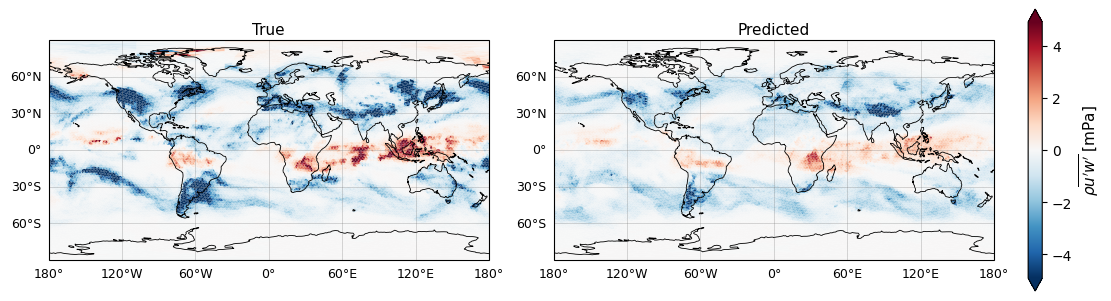

--> saved to /work/bb1097/b383521/plots/paper_plots/uw_momentum_flux_mpa_nov.png and /work/bb1097/b383521/plots/paper_plots/uw_momentum_flux_mpa_nov.pdf
Using shared color range: vmin=-1.7060, vmax=1.7060


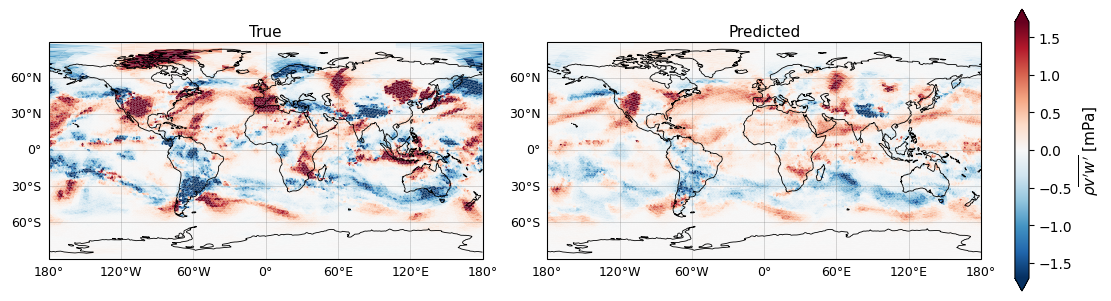

--> saved to /work/bb1097/b383521/plots/paper_plots/vw_momentum_flux_mpa_nov.png and /work/bb1097/b383521/plots/paper_plots/vw_momentum_flux_mpa_nov.pdf


In [13]:
import os
import cartopy.crs as ccrs
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr
from matplotlib.collections import PolyCollection
from matplotlib.colors import TwoSlopeNorm


def plot_global_map_flux_pair(
    var_top,
    var_bottom,
    save_dir,
    filename="global_momentum_flux_map_pair",
    title_top="True",
    title_bottom="Predicted",
    cbar_label=r"$\rho\overline{u'w'}$ [mPa]",
    cmap="RdBu_r",
    vmin=None,
    vmax=None,
    percentile_clip=True,
    p_low=2,
    p_high=98,
    symmetric=True,
    fontsize=11,
):
    var_top = np.asarray(var_top, dtype=float)
    var_bottom = np.asarray(var_bottom, dtype=float)

    gridfil = xr.open_dataset(
        "/work/bb1097/b381585/data/icon_grid_0012_R02B04_G.nc"
    )
    clon_vertices = np.rad2deg(gridfil.clon_vertices.values)
    clat_vertices = np.rad2deg(gridfil.clat_vertices.values)
    gridfil.close()

    clon_vertices = np.where(
        clon_vertices < -180.0, clon_vertices + 360.0, clon_vertices
    )
    clon_vertices = np.where(
        clon_vertices > 180.0, clon_vertices - 360.0, clon_vertices
    )
    triangles = np.stack([clon_vertices, clat_vertices], axis=-1)

    # ---------------------------
    # Shared color range across BOTH panels
    # ---------------------------
    if vmin is None or vmax is None:
        combined = np.concatenate(
            [var_top[np.isfinite(var_top)], var_bottom[np.isfinite(var_bottom)]]
        )
        if percentile_clip:
            p_lo_val, p_hi_val = np.nanpercentile(combined, [p_low, p_high])
            if symmetric:
                vmax_abs = max(abs(p_lo_val), abs(p_hi_val))
                vmin, vmax = -vmax_abs, vmax_abs
            else:
                vmin, vmax = p_lo_val, p_hi_val
        else:
            vmin, vmax = np.nanmin(combined), np.nanmax(combined)

    print(f"Using shared color range: vmin={vmin:.4f}, vmax={vmax:.4f}")

    cmap_obj = plt.get_cmap(cmap)
    norm = TwoSlopeNorm(vmin=vmin, vcenter=0.0, vmax=vmax)

    # 1 row, 2 columns side-by-side layout (wide format for two panels in a row)
    fig, axes = plt.subplots(
        1,
        2,
        figsize=(11.0, 3.4),
        subplot_kw=dict(projection=ccrs.PlateCarree()),
        constrained_layout=True,
    )

    datasets = [
        (var_top, title_top, axes[0]),
        (var_bottom, title_bottom, axes[1]),
    ]

    for var, subtitle, ax in datasets:
        colors = cmap_obj(norm(var))
        colors[~np.isfinite(var)] = [1, 1, 1, 0]

        ax.set_global()
        ax.coastlines(linewidth=0.6, zorder=2)

        gl = ax.gridlines(
            draw_labels=True,
            linewidth=0.4,
            color="dimgray",
            alpha=0.45,
            zorder=2,
        )
        gl.top_labels = False
        gl.right_labels = False
        gl.xlabel_style = {"size": fontsize - 2}
        gl.ylabel_style = {"size": fontsize - 2}

        coll = PolyCollection(
            triangles,
            fc=colors,
            edgecolors="none",
            linewidth=0.05,
            transform=ccrs.Geodetic(),
            zorder=0,
        )
        ax.add_collection(coll)

        # Unbolded subpanel title
        ax.set_title(subtitle, fontsize=fontsize, pad=4)

    sm = plt.cm.ScalarMappable(cmap=cmap_obj, norm=norm)
    sm.set_array([])

    # Single vertical colorbar to the right of both row panels
    cbar = fig.colorbar(
        sm,
        ax=axes,
        orientation="vertical",
        fraction=0.025,
        pad=0.02,
        shrink=0.85,
        extend="both",
    )
    cbar.set_label(cbar_label, fontsize=fontsize, fontweight="normal")
    cbar.ax.tick_params(labelsize=fontsize - 1)

    os.makedirs(save_dir, exist_ok=True)
    outpath_png = os.path.join(save_dir, f"{filename}.png")
    outpath_pdf = os.path.join(save_dir, f"{filename}.pdf")

    plt.savefig(outpath_png, dpi=400, bbox_inches="tight")
    plt.savefig(outpath_pdf, dpi=400, bbox_inches="tight")
    plt.show()
    print(f"--> saved to {outpath_png} and {outpath_pdf}")


# --- uw: January ---
plot_global_map_flux_pair(
    uw_test * 1000,
    uw_pred * 1000,
    save_dir="/work/bb1097/b383521/plots/paper_plots/",
    filename="uw_momentum_flux_mpa_nov",
    title_top="True",
    title_bottom="Predicted",
    cbar_label=r"$\rho\overline{u'w'}$ [mPa]",
    symmetric=True,
)

plot_global_map_flux_pair(
    vw_test * 1000,
    vw_pred * 1000,
    save_dir="/work/bb1097/b383521/plots/paper_plots/",
    filename="vw_momentum_flux_mpa_nov",
    title_top="True",
    title_bottom="Predicted",
    cbar_label=r"$\rho\overline{v'w'}$ [mPa]",
    symmetric=True,
)